# Evaluating Stability of XAI Methods in Sentiment Analysis under Noisy Social Media Text

### A Comparative Study of LIME and SHAP for Explaining Transformer-based Models on Noisy Twitter Data

**Author:** Nikita Lakhani  
**Programme:** M.Sc. Big Data & AI, SRH University Heidelberg (Leipzig Campus)  
**Supervisors:** Dr. Prof. Ghanbarnejad, Fakhteh & Mrs. Shamli

---

## How to use this notebook

This notebook is organised into clear sections. Each section has a title and explains what it does.

> ### ⚠️ EVERY SESSION — run these 2 cells first:
> 1. **Cell A — Session Starter** (mounts Drive, loads data + trained BERT model)
> 2. **Cell B — Setup LIME & SHAP** (only needed before running LIME/SHAP/noise sections)
>
> Google Colab sessions expire after a few hours. When that happens, just re-run Cell A and Cell B — all your saved results, model, and data reload automatically from Google Drive. Nothing is lost.

---

## Notebook structure

| Section | What it does | Run when |
|---------|-------------|----------|
| **A. Session Starter** | Mount Drive, load data + model | Every session |
| **B. Setup LIME & SHAP** | Define explainers | Every session (before XAI) |
| **1. EDA** | Explore the dataset | Once |
| **2. EDA Statistics** | Mean, SD, skewness | Once |
| **3. BERT Fine-Tuning** | Train the model | Once (~18 min) |
| **4. Sample Selection** | Pick 200 balanced tweets | Once |
| **5. Noise Injection + LIME/SHAP** | Main experiment (checkpointed) | Once (~6 hrs, resumable) |
| **6. Final Analysis** | Compute all 4 metrics + stats | Once |
| **7. RQ1 Run-to-Run** | Reproducibility test | Once (~14 hrs, resumable) |
| **8. Final Charts** | Publication-quality figures | Anytime |


---
# 🟢 SECTION A — SESSION STARTER
### ⚠️ RUN THIS FIRST, EVERY SESSION

This single cell does everything needed to start working:
- Mounts your Google Drive
- Defines all folder paths
- Imports all libraries
- Loads the TweetEval dataset
- Loads your trained BERT model from Drive

Wait until you see **"Model loaded: ✅ Yes"** before running anything else.

In [ ]:
# ══════════════════════════════════════════════
# SESSION STARTER — Run this FIRST every session
# ══════════════════════════════════════════════

# ── 1. Mount Drive ──
from google.colab import drive
drive.mount('/content/drive')

# ── 2. All paths ──
import os
BASE        = '/content/drive/MyDrive/thesis_xai_stability'
FIG_EDA     = f'{BASE}/figures/eda'
FIG_NOISE   = f'{BASE}/figures/noise'
FIG_RESULTS = f'{BASE}/figures/results'
FIG_XAI     = f'{BASE}/figures/xai'
DATA_DIR    = f'{BASE}/data'
MODEL_DIR   = f'{BASE}/models'
RESULTS_DIR = f'{BASE}/results'

# Create folders if missing
for folder in [FIG_EDA, FIG_NOISE, FIG_RESULTS,
               FIG_XAI, DATA_DIR, MODEL_DIR, RESULTS_DIR]:
    os.makedirs(folder, exist_ok=True)

# ── 3. All imports ──
import torch
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from datasets import load_dataset
from transformers import (
    BertTokenizer,
    BertForSequenceClassification
)
from sklearn.metrics import (
    classification_report, f1_score,
    precision_score, recall_score, accuracy_score
)
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer

# ── 4. GPU check ──
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'No GPU'

# ── 5. Load dataset ──
print('Loading TweetEval dataset...')
dataset = load_dataset('cardiffnlp/tweet_eval', 'sentiment')
df_train = pd.DataFrame(dataset['train'])
df_val   = pd.DataFrame(dataset['validation'])
df_test  = pd.DataFrame(dataset['test'])

label_map = {0:'Negative', 1:'Neutral', 2:'Positive'}
for df in [df_train, df_val, df_test]:
    df['label_name'] = df['label'].map(label_map)

df_train_clean = df_train.drop_duplicates(
    subset='text', keep='first'
).reset_index(drop=True)

# ── 6. Load saved BERT model ──
print('Loading saved BERT model from Drive...')
model_path = f'{MODEL_DIR}/bert_finetuned'

if os.path.exists(model_path):
    tokenizer = BertTokenizer.from_pretrained(model_path)
    model     = BertForSequenceClassification.from_pretrained(model_path)
    model     = model.to(device)
    print(f'✅ BERT model loaded from Drive!')
else:
    print('⚠️  No saved model found — need to retrain')
    tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

model.eval()
print('✅ Model in eval mode — ready for LIME & SHAP!')

# ── 7. Print summary ──
print()
print('=' * 50)
print('SESSION READY!')
print('=' * 50)
print(f'  GPU          : {gpu_name}')
print(f'  Device       : {device}')
print(f'  Train tweets : {len(df_train_clean):,}')
print(f'  Val tweets   : {len(df_val):,}')
print(f'  Test tweets  : {len(df_test):,}')
print(f'  Model path   : {model_path}')
print(f'  Model loaded : {"✅ Yes" if os.path.exists(model_path) else "❌ No"}')
print('=' * 50)
print()
print('All variables ready:')
print('  df_train_clean, df_val, df_test')
print('  model, tokenizer, device')
print('  BASE, MODEL_DIR, RESULTS_DIR, FIG_EDA...')

Mounted at /content/drive
Loading TweetEval dataset...


README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (4 outputs left out)

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Loading saved BERT model from Drive...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✅ BERT model loaded from Drive!
✅ Model in eval mode — ready for LIME & SHAP!

SESSION READY!
  GPU          : Tesla T4
  Device       : cuda
  Train tweets : 45,586
  Val tweets   : 2,000
  Test tweets  : 12,284
  Model path   : /content/drive/MyDrive/thesis_xai_stability/models/bert_finetuned
  Model loaded : ✅ Yes

All variables ready:
  df_train_clean, df_val, df_test
  model, tokenizer, device
  BASE, MODEL_DIR, RESULTS_DIR, FIG_EDA...


In [ ]:
df.head(10)

,text,label,label_name
0,@user @user what do these '1/2 naked pics' hav...,1,Neutral
1,OH: “I had a blue penis while I was this” [pla...,1,Neutral
2,"@user @user That's coming, but I think the vic...",1,Neutral
3,I think I may be finally in with the in crowd ...,2,Positive
4,"@user Wow,first Hugo Chavez and now Fidel Cast...",0,Negative
5,Savchenko now Saakashvili took drug test live ...,1,Neutral
6,How many more days until opening day? 😩,1,Neutral
7,Twitter's #ThankYouObama Shows Heartfelt Grati...,2,Positive
8,All CSG and Fracking all around Australia is t...,1,Neutral
9,@user @user @user @user @user @user take away ...,0,Negative


---
# 🟢 SECTION B — SETUP LIME & SHAP
### ⚠️ RUN THIS SECOND, EVERY SESSION (before any LIME/SHAP work)

This defines:
- `predict_proba()` — the function that feeds tweets to BERT and returns probabilities
- `lime_explainer` — the LIME text explainer
- `shap_explainer` — the SHAP Partition explainer

You need this before running Sections 5, 6, 7, or 8.

In [ ]:
# Setup explainers (run after session starter)
!pip install lime shap nlpaug -q

import lime
from lime.lime_text import LimeTextExplainer
import shap
import torch
import numpy as np

# Prediction function
def predict_proba(texts):
    if isinstance(texts, np.ndarray):
        texts = texts.tolist()
    clean = []
    for t in texts:
        if isinstance(t, list):
            clean.append(' '.join(str(w) for w in t))
        else:
            clean.append(str(t))
    inputs = tokenizer(clean, return_tensors='pt', truncation=True,
                       padding=True, max_length=128)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = model(**inputs)
    return torch.nn.functional.softmax(outputs.logits, dim=1).cpu().numpy()

# LIME
lime_explainer = LimeTextExplainer(
    class_names=['Negative','Neutral','Positive'], random_state=42)

# SHAP
masker = shap.maskers.Text(r'\s+')
shap_explainer = shap.explainers.Partition(
    predict_proba, masker,
    output_names=['Negative','Neutral','Positive'])

print('✅ LIME and SHAP explainers ready!')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 14.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 kB 32.4 MB/s eta 0:00:00
✅ LIME and SHAP explainers ready!


---
# 📊 SECTION 1 — EXPLORATORY DATA ANALYSIS (EDA)

Understand the TweetEval dataset before modelling. Run these cells once.
Results are saved to `figures/eda/` in your Drive.

### 1.0 — EDA Imports
Run this once before the EDA cells. It loads matplotlib, seaborn, and wordcloud (the Session Starter only loads plotly).

In [ ]:
# EDA plotting libraries (matplotlib, seaborn, wordcloud)
# The Session Starter loads plotly; these are needed for the EDA charts below.
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from transformers import BertTokenizer

plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size']  = 11
sns.set_style('whitegrid')

print('✅ EDA plotting libraries ready!')


✅ EDA plotting libraries ready!


### 1.1 — Data Quality Check
Checks for missing values, duplicates, and train-test leakage.

In [ ]:
# ══════════════════════════════════════════════════════════════
# EDA CELL 1 — Data Quality Check
# Missing values, duplicates, label verification
# ══════════════════════════════════════════════════════════════

print('=' * 60)
print('EDA STEP 1: DATA QUALITY CHECK')
print('=' * 60)

for name, df in [('Train', df_train), ('Val', df_val), ('Test', df_test)]:
    print(f'\n── {name} Set ──')
    print(f'  Shape:       {df.shape}')
    print(f'  Nulls:       {df.isnull().sum().sum()}')
    print(f'  Duplicates:  {df.duplicated(subset="text").sum()}')
    print(f'  Labels seen: {sorted(df["label"].unique())}')

# Cross-split duplicate check (data leakage)
train_texts = set(df_train['text'])
test_texts  = set(df_test['text'])
overlap     = train_texts & test_texts
print(f'\n  Train-Test overlap (leakage check): {len(overlap)} tweets')

print('\n✅ Data quality check complete')

EDA STEP 1: DATA QUALITY CHECK

── Train Set ──
  Shape:       (45615, 3)
  Nulls:       0
  Duplicates:  29
  Labels seen: [np.int64(0), np.int64(1), np.int64(2)]

── Val Set ──
  Shape:       (2000, 3)
  Nulls:       0
  Duplicates:  0
  Labels seen: [np.int64(0), np.int64(1), np.int64(2)]

── Test Set ──
  Shape:       (12284, 3)
  Nulls:       0
  Duplicates:  0
  Labels seen: [np.int64(0), np.int64(1), np.int64(2)]

  Train-Test overlap (leakage check): 0 tweets

✅ Data quality check complete


### 1.2 — Class Distribution (Before Cleaning)
Grouped bar chart across Train / Validation / Test. Justifies using Macro F1 due to class imbalance.

In [ ]:
# ══════════════════════════════════════════════════════════════
# EDA 1.2 — Class Distribution BEFORE Cleaning (Figure 1)
# Grouped bar chart across Train / Val / Test splits
# ══════════════════════════════════════════════════════════════
import plotly.graph_objects as go

CLASS_COLORS = {'Negative':'#C0392B', 'Neutral':'#7F8C8D', 'Positive':'#1A8A5A'}
splits = {'Train': df_train, 'Validation': df_val, 'Test': df_test}

fig = go.Figure()
all_vals = []
for cls in ['Negative','Neutral','Positive']:
    counts = [ (s['label_name']==cls).sum() for s in splits.values() ]
    all_vals += counts
    fig.add_trace(go.Bar(
        name=cls, x=list(splits.keys()), y=counts,
        marker_color=CLASS_COLORS[cls],
        text=counts, texttemplate='%{text:,}', textposition='outside',
    ))

ymax = max(all_vals)
fig.update_layout(
    title_text='Figure 1 — Class Distribution Across All Splits (BEFORE Cleaning)',
    barmode='group', plot_bgcolor='white', height=480,
    xaxis_title='Split', yaxis_title='Count',
    yaxis=dict(range=[0, ymax * 1.15]),     # headroom for labels
    legend=dict(orientation='h', y=1.12, x=0.35),
    margin=dict(t=90),
)
fig.write_html(f'{FIG_EDA}/fig1_class_dist_before.html')
fig.show()

print('Class counts (training set):')
print(df_train['label_name'].value_counts())


Class counts (training set):
label_name
Neutral     20673
Positive    17849
Negative     7093
Name: count, dtype: int64


### 1.3 — Effect of Duplicate Removal
Shows training-set class counts before vs after removing duplicate tweets.

In [ ]:
# ══════════════════════════════════════════════════════════════
# EDA 1.3 — Effect of Duplicate Removal (Figure 4)
# Training set: before vs after cleaning
# ══════════════════════════════════════════════════════════════
import plotly.graph_objects as go

before_counts = [ (df_train['label_name']==c).sum() for c in ['Negative','Neutral','Positive'] ]
after_counts  = [ (df_train_clean['label_name']==c).sum() for c in ['Negative','Neutral','Positive'] ]
n_removed = len(df_train) - len(df_train_clean)

fig = go.Figure()
fig.add_trace(go.Bar(name='Before cleaning', x=['Negative','Neutral','Positive'],
    y=before_counts, marker_color='#95A5A6',
    text=before_counts, texttemplate='%{text:,}', textposition='outside'))
fig.add_trace(go.Bar(name='After cleaning', x=['Negative','Neutral','Positive'],
    y=after_counts, marker_color='#E8431A',
    text=after_counts, texttemplate='%{text:,}', textposition='outside'))

ymax = max(before_counts + after_counts)
fig.update_layout(
    title_text=f'Figure 4 — Before vs After Cleaning (Training Set) · {n_removed} duplicates removed',
    barmode='group', plot_bgcolor='white', height=480,
    xaxis_title='Sentiment', yaxis_title='Count',
    yaxis=dict(range=[0, ymax * 1.15]),     # headroom so labels aren't cut
    legend=dict(orientation='h', y=1.12, x=0.30),
    margin=dict(t=90),
)
fig.write_html(f'{FIG_EDA}/fig4_dedup_effect.html')
fig.show()
print(f'Duplicates removed: {n_removed}')
print(f'Train before: {len(df_train):,}  →  after: {len(df_train_clean):,}')


Duplicates removed: 29
Train before: 45,615  →  after: 45,586


### 1.4 — Tweet Length Distributions (with Normalized Density Curve)
Character, word, and BERT-token length histograms **with KDE density curves**. This is the normalized distribution chart. Confirms tweets fit the 128-token limit.

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

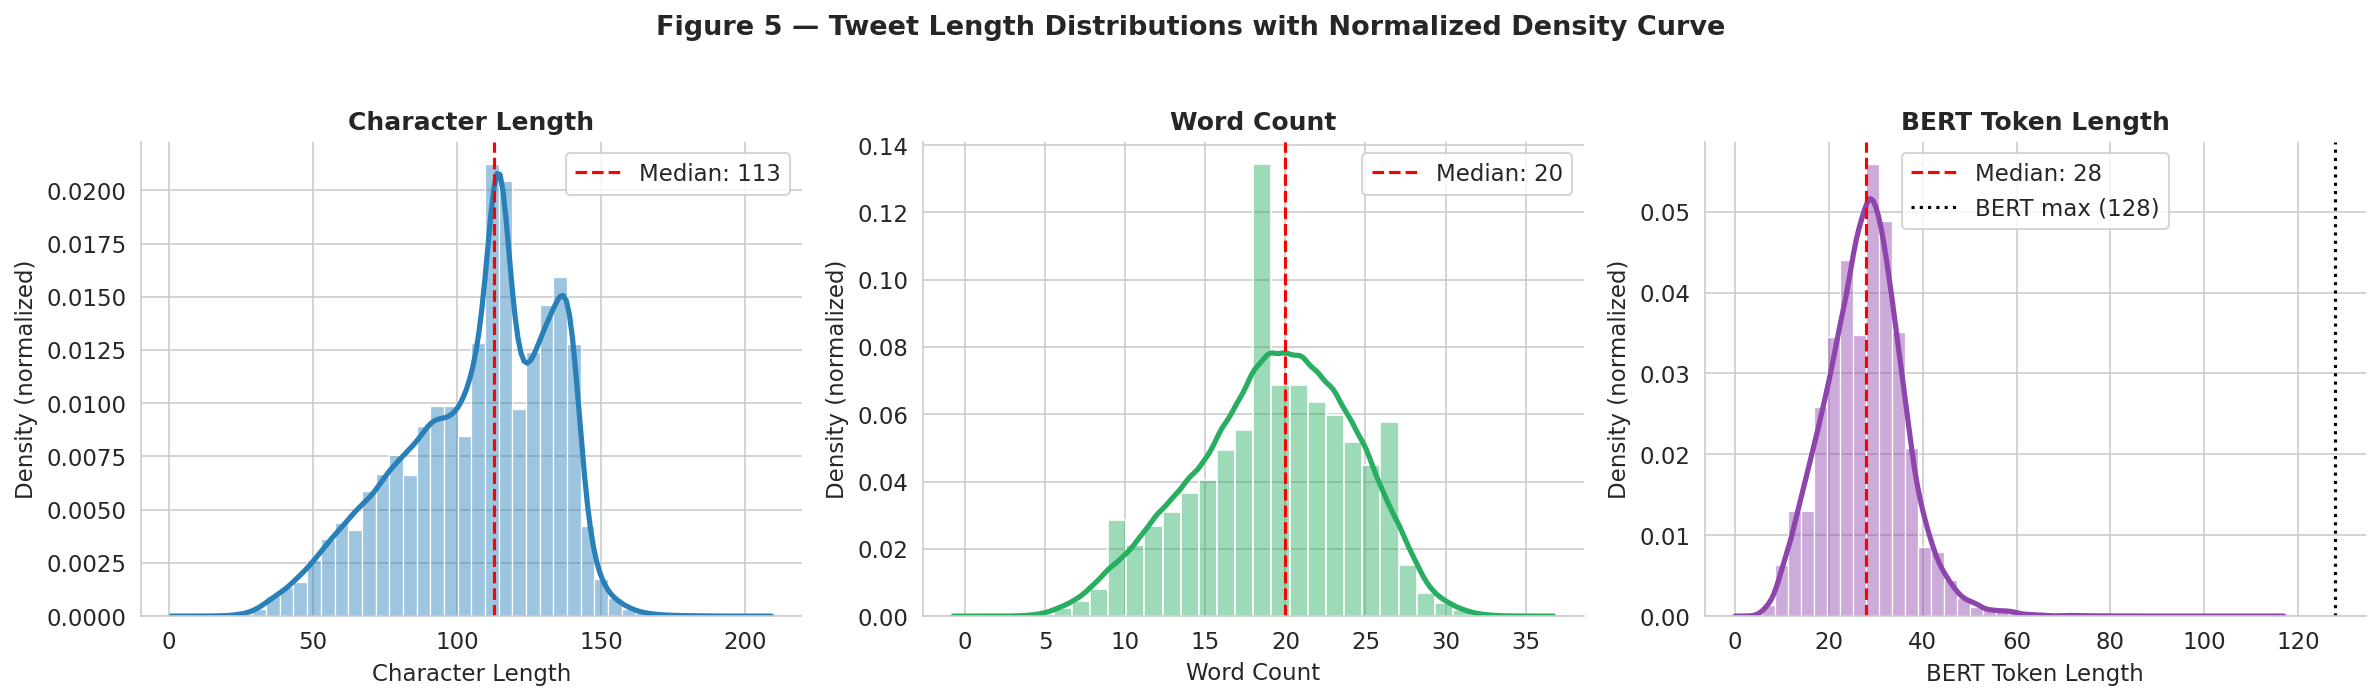

✅ Length columns computed and saved to df_train_clean


In [ ]:
# ══════════════════════════════════════════════════════════════
# EDA 1.4 — Tweet Length Distributions WITH Normalized Density (Figure 5)
# Character, Word, and BERT Token length — histogram + KDE density curve
# ══════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import BertTokenizer

# Compute lengths on clean training data
tok = BertTokenizer.from_pretrained('bert-base-uncased')
d = df_train_clean.copy()
d['char_len']  = d['text'].str.len()
d['word_len']  = d['text'].str.split().str.len()
d['token_len'] = d['text'].apply(lambda x: len(tok.tokenize(str(x))))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
specs = [
    ('char_len',  'Character Length', '#2980B9', 40),
    ('word_len',  'Word Count',       '#27AE60', 30),
    ('token_len', 'BERT Token Length','#8E44AD', 40),
]
for ax, (col, title, color, bins) in zip(axes, specs):
    # Histogram + KDE density curve overlaid (normalized)
    sns.histplot(d[col], bins=bins, color=color, alpha=0.45,
                 stat='density', edgecolor='white', ax=ax)
    sns.kdeplot(d[col], color=color, linewidth=2.5, ax=ax)
    # Median line
    med = d[col].median()
    ax.axvline(med, color='red', linestyle='--', linewidth=1.5,
               label=f'Median: {med:.0f}')
    ax.set_title(title, fontweight='bold', fontsize=12)
    ax.set_xlabel(title)
    ax.set_ylabel('Density (normalized)')
    ax.legend()
    sns.despine(ax=ax)

# Mark BERT 128-token limit on token panel
axes[2].axvline(128, color='black', linestyle=':', linewidth=1.5, label='BERT max (128)')
axes[2].legend()

plt.suptitle('Figure 5 — Tweet Length Distributions with Normalized Density Curve',
             fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(f'{FIG_EDA}/fig5_length_density.png', dpi=150, bbox_inches='tight')
plt.show()

# Keep the lengths on df_train_clean for the next cell
df_train_clean['char_len']  = d['char_len']
df_train_clean['word_len']  = d['word_len']
df_train_clean['token_len'] = d['token_len']
print('✅ Length columns computed and saved to df_train_clean')


### 1.5 — Token Length by Sentiment + Statistics Table
Box plot per class plus a descriptive statistics table (mean, median, SD, IQR, % over 128 tokens).

/tmp/ipykernel_2513/1820997977.py:21: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




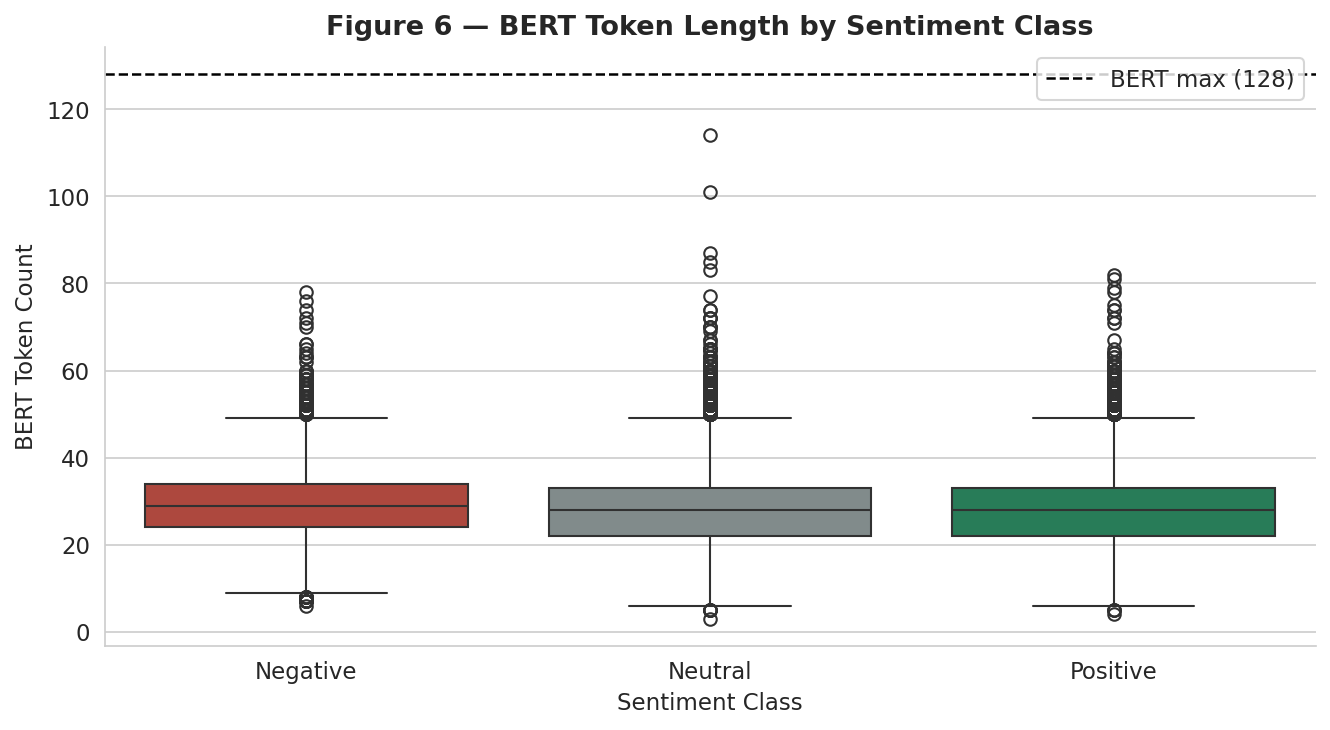

Figure 6b — Token Length Statistics by Sentiment Class
   Class  Count  Mean  Median  Std Dev  Min  Max  IQR >128 tok
Negative  7,091  29.0      29      8.2    6   78   10 0 (0.0%)
 Neutral 20,655  27.6      28      8.6    3  114   11 0 (0.0%)
Positive 17,840  27.6      28      8.4    4   82   11 0 (0.0%)

✅ Saved token stats table


In [ ]:
# ══════════════════════════════════════════════════════════════
# EDA 1.5 — Token Length by Sentiment + Statistics Table (Figure 6 + 6b)
# Box plot per class AND a descriptive statistics table
# ══════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure token_len exists
if 'token_len' not in df_train_clean.columns:
    from transformers import BertTokenizer
    tok = BertTokenizer.from_pretrained('bert-base-uncased')
    df_train_clean['token_len'] = df_train_clean['text'].apply(
        lambda x: len(tok.tokenize(str(x))))

order = ['Negative','Neutral','Positive']
colors = ['#C0392B','#7F8C8D','#1A8A5A']

# ── Box plot ──
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df_train_clean, x='label_name', y='token_len',
            order=order, palette=colors, ax=ax)
ax.axhline(128, color='black', linestyle='--', linewidth=1.2, label='BERT max (128)')
ax.set_title('Figure 6 — BERT Token Length by Sentiment Class',
             fontweight='bold', fontsize=13)
ax.set_xlabel('Sentiment Class'); ax.set_ylabel('BERT Token Count')
ax.legend(); sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(f'{FIG_EDA}/fig6_token_by_class.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Descriptive statistics table (Figure 6b) ──
print('=' * 60)
print('Figure 6b — Token Length Statistics by Sentiment Class')
print('=' * 60)
stats = []
for cls in order:
    s = df_train_clean[df_train_clean['label_name']==cls]['token_len']
    stats.append({
        'Class'    : cls,
        'Count'    : f'{len(s):,}',
        'Mean'     : round(s.mean(),1),
        'Median'   : int(s.median()),
        'Std Dev'  : round(s.std(),1),
        'Min'      : int(s.min()),
        'Max'      : int(s.max()),
        'IQR'      : int(s.quantile(0.75) - s.quantile(0.25)),
        '>128 tok' : f'{(s>128).sum()} ({(s>128).mean()*100:.1f}%)',
    })
stats_df = pd.DataFrame(stats)
print(stats_df.to_string(index=False))
stats_df.to_csv(f'{RESULTS_DIR}/eda_token_stats_by_class.csv', index=False)
print()
print('✅ Saved token stats table')


### 1.6 — Most Frequent Words per Sentiment
Top 10 words per class with stopwords removed. Reveals the vocabulary-overlap finding (Neutral shares words with Positive and Negative).

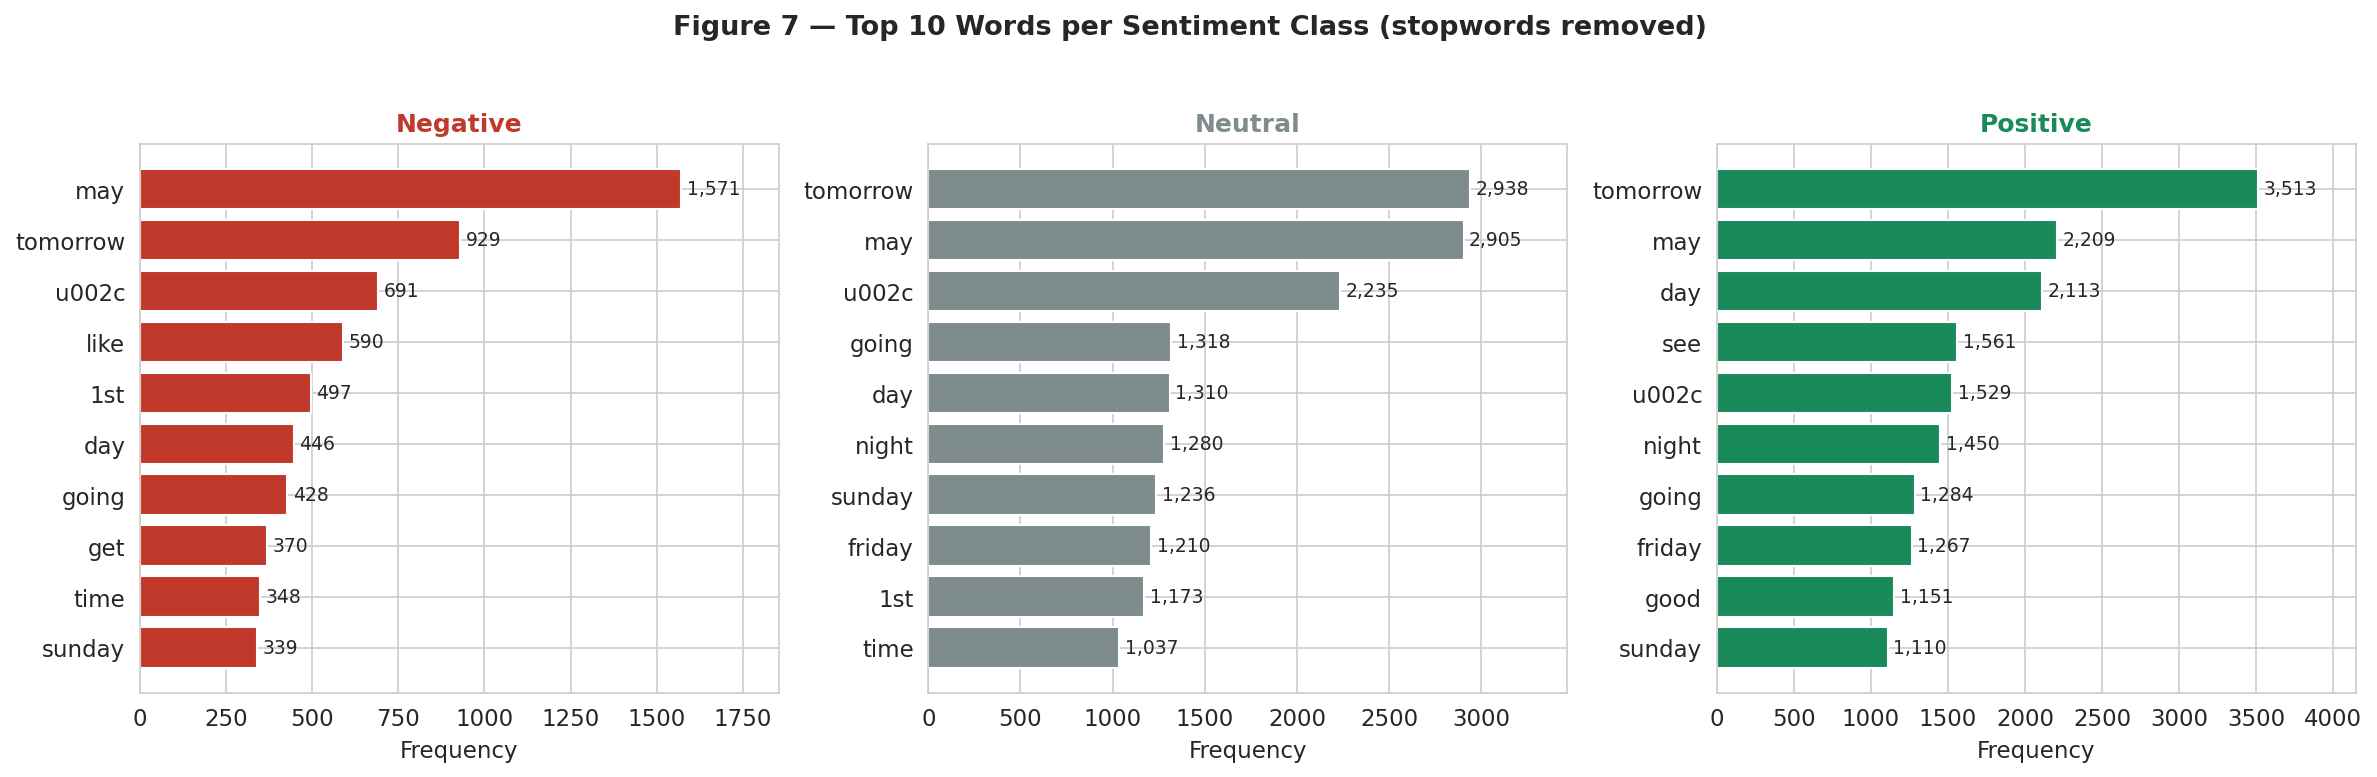

✅ Top words chart saved


In [ ]:
# ══════════════════════════════════════════════════════════════
# EDA 1.6 — Most Frequent Words per Sentiment (Figure 7)
# Stopwords removed — shows vocabulary overlap finding
# ══════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

stop = set(stopwords.words('english'))
# Add Twitter-specific noise words
stop.update(['user','rt','amp','http','https','co','via','im','dont','u','2','4'])

order = ['Negative','Neutral','Positive']
colors = ['#C0392B','#7F8C8D','#1A8A5A']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, cls, color in zip(axes, order, colors):
    texts = df_train_clean[df_train_clean['label_name']==cls]['text']
    vec = CountVectorizer(stop_words=list(stop), max_features=10)
    X = vec.fit_transform(texts.astype(str))
    freqs = X.sum(axis=0).A1
    words = vec.get_feature_names_out()
    pairs = sorted(zip(words, freqs), key=lambda x: x[1])
    w = [p[0] for p in pairs]; f = [p[1] for p in pairs]
    bars = ax.barh(w, f, color=color, edgecolor='white')
    # Value labels at end of each bar
    for bar, val in zip(bars, f):
        ax.text(bar.get_width() + max(f)*0.01, bar.get_y() + bar.get_height()/2,
                f'{val:,}', va='center', fontsize=9)
    ax.set_xlim(0, max(f) * 1.18)          # headroom so labels don't clip
    ax.set_title(f'{cls}', fontweight='bold', fontsize=12, color=color)
    ax.set_xlabel('Frequency')
plt.suptitle('Figure 7 — Top 10 Words per Sentiment Class (stopwords removed)',
             fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(f'{FIG_EDA}/fig7_top_words.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Top words chart saved')


---
# 📐 SECTION 2 — EDA STATISTICS (Mean, SD, Skewness)

Scientific descriptive statistics for tweet lengths: mean, median, standard deviation,
skewness, and distribution shape (normal vs skewed). Saved to `results/eda_statistics.csv`.

In [ ]:
# ══════════════════════════════════════════════════
# EDA STATISTICS — Mean, SD, Median, Skewness, Distribution
# Scientific description of tweet lengths
# ══════════════════════════════════════════════════

import pandas as pd
import numpy as np
from scipy.stats import skew, kurtosis
from transformers import BertTokenizer

# ── Make sure we have length columns ──
# (recompute if not already in df_train_clean)
if 'char_len' not in df_train_clean.columns:
    print('Computing length columns...')
    tokenizer_eda = BertTokenizer.from_pretrained('bert-base-uncased')
    df_train_clean = df_train_clean.copy()
    df_train_clean['char_len']  = df_train_clean['text'].str.len()
    df_train_clean['word_len']  = df_train_clean['text'].str.split().str.len()
    df_train_clean['token_len'] = df_train_clean['text'].apply(
        lambda x: len(tokenizer_eda.tokenize(str(x))))
    print('✅ Length columns ready')

# ── Compute full statistics for each length measure ──
measures = {
    'Character Length': 'char_len',
    'Word Count':       'word_len',
    'BERT Token Length':'token_len',
}

print('=' * 70)
print('EDA STATISTICAL SUMMARY — Tweet Lengths (n=45,586 clean train)')
print('=' * 70)

stats_rows = []
for name, col in measures.items():
    data = df_train_clean[col].dropna()

    mean_v   = data.mean()
    median_v = data.median()
    std_v    = data.std()
    min_v    = data.min()
    max_v    = data.max()
    skew_v   = skew(data)
    kurt_v   = kurtosis(data)

    # Determine distribution shape from skewness
    if abs(skew_v) < 0.5:
        shape = 'Approximately Normal (symmetric)'
    elif skew_v >= 0.5:
        shape = 'Right-skewed (right tail)'
    else:
        shape = 'Left-skewed (left tail)'

    # Mean vs median check
    if mean_v > median_v * 1.02:
        mvm = 'Mean > Median → right tail'
    elif mean_v < median_v * 0.98:
        mvm = 'Mean < Median → left tail'
    else:
        mvm = 'Mean ≈ Median → symmetric'

    print(f'\n{name}:')
    print(f'  Mean              : {mean_v:.2f}')
    print(f'  Median            : {median_v:.2f}')
    print(f'  Standard Deviation: {std_v:.2f}')
    print(f'  Min / Max         : {min_v:.0f} / {max_v:.0f}')
    print(f'  Skewness          : {skew_v:.3f}')
    print(f'  Kurtosis          : {kurt_v:.3f}')
    print(f'  Distribution shape: {shape}')
    print(f'  Mean vs Median    : {mvm}')

    stats_rows.append({
        'Measure'   : name,
        'Mean'      : round(mean_v, 2),
        'Median'    : round(median_v, 2),
        'Std Dev'   : round(std_v, 2),
        'Min'       : int(min_v),
        'Max'       : int(max_v),
        'Skewness'  : round(skew_v, 3),
        'Shape'     : shape,
    })

# ── Save as table ──
stats_df = pd.DataFrame(stats_rows)
stats_df.to_csv(f'{RESULTS_DIR}/eda_statistics.csv', index=False)

print()
print('=' * 70)
print('INTERPRETATION GUIDE (for thesis & professor):')
print('=' * 70)
print('• Skewness near 0      → normal/symmetric distribution')
print('• Skewness > 0.5       → right-skewed (tail on right, a few long tweets)')
print('• Skewness < -0.5      → left-skewed (tail on left, a few short tweets)')
print('• Std Dev              → how spread out lengths are around the mean')
print('• Mean > Median        → confirms right tail (long tweets pull mean up)')
print()
print(f'✅ Saved: {RESULTS_DIR}/eda_statistics.csv')

EDA STATISTICAL SUMMARY — Tweet Lengths (n=45,586 clean train)

Character Length:
  Mean              : 106.94
  Median            : 113.00
  Standard Deviation: 26.25
  Min / Max         : 10 / 200
  Skewness          : -0.573
  Kurtosis          : -0.316
  Distribution shape: Left-skewed (left tail)
  Mean vs Median    : Mean < Median → left tail

Word Count:
  Mean              : 19.24
  Median            : 20.00
  Standard Deviation: 4.94
  Min / Max         : 1 / 35
  Skewness          : -0.256
  Kurtosis          : -0.383
  Distribution shape: Approximately Normal (symmetric)
  Mean vs Median    : Mean < Median → left tail

BERT Token Length:
  Mean              : 27.81
  Median            : 28.00
  Standard Deviation: 8.48
  Min / Max         : 3 / 114
  Skewness          : 0.406
  Kurtosis          : 1.378
  Distribution shape: Approximately Normal (symmetric)
  Mean vs Median    : Mean ≈ Median → symmetric

INTERPRETATION GUIDE (for thesis & professor):
• Skewness near 0      

---
# 🤖 SECTION 3 — BERT FINE-TUNING

Trains `bert-base-uncased` on TweetEval sentiment (3 classes).
**Takes ~18 minutes on a T4 GPU.** The model is saved to Drive at the end of the
same cell, so it survives session expiry. Run this **once**.

> After training once, you never need this section again — the Session Starter (Section A)
> reloads the saved model automatically.

In [ ]:
# ══════════════════════════════════════════════════
# COMPLETE BERT TRAINING + SAVE IN ONE CELL
# ~18 minutes — keep Colab tab open!
# ══════════════════════════════════════════════════

from torch.utils.data import Dataset
from transformers import (
    TrainingArguments, Trainer, EarlyStoppingCallback
)

# ── Tokenize ──
print('Step 1/5 — Tokenizing...')
MAX_LEN = 128

def tokenize(texts, labels):
    enc = tokenizer(
        list(texts), truncation=True, padding=True,
        max_length=MAX_LEN, return_tensors='pt'
    )
    return enc, torch.tensor(list(labels), dtype=torch.long)

train_enc, train_lbl = tokenize(df_train_clean['text'], df_train_clean['label'])
val_enc,   val_lbl   = tokenize(df_val['text'],         df_val['label'])
test_enc,  test_lbl  = tokenize(df_test['text'],        df_test['label'])
print(f'   Train: {train_enc["input_ids"].shape} ✅')

# ── Dataset class ──
class TweetDataset(Dataset):
    def __init__(self, enc, lbl):
        self.enc = enc
        self.lbl = lbl
    def __len__(self):
        return len(self.lbl)
    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.enc.items()}
        item['labels'] = self.lbl[idx]
        return item

train_dataset = TweetDataset(train_enc, train_lbl)
val_dataset   = TweetDataset(val_enc,   val_lbl)
test_dataset  = TweetDataset(test_enc,  test_lbl)
print('Step 2/5 — Datasets created ✅')

# ── Load fresh BERT model ──
print('Step 3/5 — Loading BERT...')
model = BertForSequenceClassification.from_pretrained(
    'bert-base-uncased',
    num_labels=3,
    id2label={0:'Negative', 1:'Neutral', 2:'Positive'},
    label2id={'Negative':0, 'Neutral':1, 'Positive':2},
    ignore_mismatched_sizes=True,
)
model = model.to(device)
print(f'   Parameters: {sum(p.numel() for p in model.parameters()):,} ✅')

# ── Metrics ──
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        'macro_f1'       : round(f1_score(labels, preds, average='macro'), 4),
        'macro_precision': round(precision_score(labels, preds, average='macro', zero_division=0), 4),
        'macro_recall'   : round(recall_score(labels, preds, average='macro'), 4),
        'accuracy'       : round(accuracy_score(labels, preds), 4),
    }

# ── Training arguments ──
training_args = TrainingArguments(
    output_dir          = f'{MODEL_DIR}/bert_checkpoints',
    num_train_epochs    = 3,
    learning_rate       = 2e-5,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size  = 32,
    eval_strategy       = 'epoch',
    save_strategy       = 'epoch',
    load_best_model_at_end      = True,
    metric_for_best_model       = 'macro_f1',
    greater_is_better   = True,
    weight_decay        = 0.01,
    warmup_ratio        = 0.1,
    logging_steps       = 100,
    report_to           = 'none',
    fp16                = True,
    dataloader_num_workers = 2,
)

# ── Trainer ──
trainer = Trainer(
    model           = model,
    args            = training_args,
    train_dataset   = train_dataset,
    eval_dataset    = val_dataset,
    compute_metrics = compute_metrics,
    callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)]
)
print('Step 4/5 — Starting training (≈18 min)...')
print('=' * 55)

# ── TRAIN ──
train_result = trainer.train()

print('=' * 55)
print(f'Training loss   : {train_result.training_loss:.4f}')
print(f'Time taken      : {train_result.metrics["train_runtime"]/60:.1f} min')

# ── Evaluate on test set ──
print()
print('Evaluating on test set...')
pred_output = trainer.predict(test_dataset)
preds       = np.argmax(pred_output.predictions, axis=1)
true        = pred_output.label_ids

macro_f1  = f1_score(true, preds, average='macro')
macro_pre = precision_score(true, preds, average='macro', zero_division=0)
macro_rec = recall_score(true, preds, average='macro')
acc       = accuracy_score(true, preds)

print()
print('=' * 55)
print('FINAL TEST SET RESULTS')
print('=' * 55)
print(f'  Macro Precision : {macro_pre:.4f} ({macro_pre*100:.2f}%)')
print(f'  Macro Recall    : {macro_rec:.4f} ({macro_rec*100:.2f}%)')
print(f'  Macro F1        : {macro_f1:.4f} ({macro_f1*100:.2f}%)  <- PRIMARY')
print(f'  Accuracy        : {acc:.4f} ({acc*100:.2f}%)')
print()
print(classification_report(
    true, preds,
    target_names=['Negative','Neutral','Positive'],
    digits=4
))

# ── SAVE MODEL IMMEDIATELY ──
print('Step 5/5 — Saving model to Drive...')
save_path = f'{MODEL_DIR}/bert_finetuned'
model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

# Save results CSV
pd.DataFrame({
    'model'           : ['bert-base-uncased'],
    'dataset'         : ['TweetEval Sentiment'],
    'train_tweets'    : [45586],
    'test_tweets'     : [12284],
    'epochs'          : [3],
    'batch_size'      : [16],
    'learning_rate'   : [2e-5],
    'macro_precision' : [round(macro_pre, 4)],
    'macro_recall'    : [round(macro_rec, 4)],
    'macro_f1'        : [round(macro_f1, 4)],
    'accuracy'        : [round(acc, 4)],
}).to_csv(f'{RESULTS_DIR}/bert_results.csv', index=False)

print()
print('=' * 55)
print('EVERYTHING COMPLETE AND SAVED!')
print('=' * 55)
print(f'  Model saved  : {save_path}')
print(f'  Results CSV  : {RESULTS_DIR}/bert_results.csv')
print()
print('Next session reload with:')
print(f'  model = BertForSequenceClassification.from_pretrained("{save_path}")')
print(f'  tokenizer = BertTokenizer.from_pretrained("{save_path}")')

Step 1/5 — Tokenizing...
   Train: torch.Size([45586, 116]) ✅
Step 2/5 — Datasets created ✅
Step 3/5 — Loading BERT...


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] warmup_

   Parameters: 109,484,547 ✅
Step 4/5 — Starting training (≈18 min)...


... (5 outputs left out)

Training loss   : 0.4991
Time taken      : 17.3 min

Evaluating on test set...



FINAL TEST SET RESULTS
  Macro Precision : 0.6907 (69.07%)
  Macro Recall    : 0.7093 (70.93%)
  Macro F1        : 0.6981 (69.81%)  <- PRIMARY
  Accuracy        : 0.6973 (69.73%)

              precision    recall  f1-score   support

    Negative     0.6859    0.7659    0.7237      3972
     Neutral     0.7242    0.6426    0.6809      5937
    Positive     0.6621    0.7196    0.6897      2375

    accuracy                         0.6973     12284
   macro avg     0.6907    0.7093    0.6981     12284
weighted avg     0.6998    0.6973    0.6965     12284

Step 5/5 — Saving model to Drive...


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


EVERYTHING COMPLETE AND SAVED!
  Model saved  : /content/drive/MyDrive/thesis_xai_stability/models/bert_finetuned
  Results CSV  : /content/drive/MyDrive/thesis_xai_stability/results/bert_results.csv

Next session reload with:
  model = BertForSequenceClassification.from_pretrained("/content/drive/MyDrive/thesis_xai_stability/models/bert_finetuned")
  tokenizer = BertTokenizer.from_pretrained("/content/drive/MyDrive/thesis_xai_stability/models/bert_finetuned")


---
# 🎯 SECTION 4 — SAMPLE SELECTION (200 balanced tweets)

Picks 200 tweets from the test set, balanced across classes (67 Negative, 67 Neutral,
66 Positive). The sample is saved to Drive so the same tweets are always used.

In [ ]:
# Pick 50 balanced tweets (17 Neg, 17 Neu, 16 Pos)
import pandas as pd
import os
CHECKPOINT_DIR = f'{BASE}/checkpoints'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

sample_file = f'{CHECKPOINT_DIR}/sample_50_tweets.csv'

if os.path.exists(sample_file):
    # Reload existing sample so we always use the SAME 50 tweets
    sample_50 = pd.read_csv(sample_file)
    print('✅ Reloaded existing 50-tweet sample')
else:
    # Create new balanced sample
    samples = []
    counts = {0: 17, 1: 17, 2: 16}  # balanced
    for label, n in counts.items():
        subset = df_test[df_test['label'] == label].sample(n, random_state=42)
        samples.append(subset)
    sample_50 = pd.concat(samples).reset_index(drop=True)
    sample_50.to_csv(sample_file, index=False)
    print('✅ Created new 50-tweet sample')

print(f'   Total: {len(sample_50)} tweets')
print(f'   Negative: {(sample_50["label"]==0).sum()}')
print(f'   Neutral : {(sample_50["label"]==1).sum()}')
print(f'   Positive: {(sample_50["label"]==2).sum()}')

✅ Reloaded existing 50-tweet sample
   Total: 50 tweets
   Negative: 17
   Neutral : 17
   Positive: 16


### 4.2 — Expand to 200 tweets (final sample)
Keeps the original 50 and adds 150 more, balanced across classes.

In [ ]:
# Expand to 200 tweets — keeping the existing 50
import pandas as pd
import os

CHECKPOINT_DIR = f'{BASE}/checkpoints'
sample_50_file  = f'{CHECKPOINT_DIR}/sample_50_tweets.csv'
sample_200_file = f'{CHECKPOINT_DIR}/sample_200_tweets.csv'

if os.path.exists(sample_200_file):
    sample_200 = pd.read_csv(sample_200_file)
    print('✅ Reloaded existing 200-tweet sample')
else:
    # Load existing 50
    sample_50 = pd.read_csv(sample_50_file)
    existing_texts = set(sample_50['text'].tolist())

    # Pick 150 MORE — balanced, excluding the 50 already used
    new_samples = []
    counts = {0: 50, 1: 50, 2: 50}  # 50 per class for the new ones

    for label, n in counts.items():
        # All test tweets of this class NOT already in our 50
        pool = df_test[
            (df_test['label'] == label) &
            (~df_test['text'].isin(existing_texts))
        ]
        # How many of this class already in the 50?
        already = (sample_50['label'] == label).sum()
        need = n - already   # top up to 50 per class total...
        # but we want ~67 per class for 200 total
        new_samples.append(pool.sample(min(need + 17, len(pool)),
                                       random_state=label))

    new_150 = pd.concat(new_samples)
    # Combine: existing 50 + new ones, cap at 200
    sample_200 = pd.concat([sample_50, new_150]).drop_duplicates(
        subset='text').head(200).reset_index(drop=True)
    sample_200.to_csv(sample_200_file, index=False)
    print('✅ Created 200-tweet sample (includes your 50)')

print(f'   Total   : {len(sample_200)} tweets')
print(f'   Negative: {(sample_200["label"]==0).sum()}')
print(f'   Neutral : {(sample_200["label"]==1).sum()}')
print(f'   Positive: {(sample_200["label"]==2).sum()}')

✅ Reloaded existing 200-tweet sample
   Total   : 200 tweets
   Negative: 67
   Neutral : 67
   Positive: 66


---
# 🔊 SECTION 5 — NOISE INJECTION + LIME/SHAP (Main Experiment)

This is the core experiment. For each of the 200 tweets, it:
1. Creates 4 noisy versions (typo, emoji, synonym, deletion)
2. Runs LIME and SHAP on the clean tweet and each noisy version
3. Computes all 4 stability metrics (Jaccard, Sign Consistency, L2, Spearman)

> ### 💾 Checkpoint-safe
> This cell **saves after every tweet** and **skips already-done tweets** on restart.
> If Colab disconnects, just re-run the cell — it continues where it stopped.
> Full run takes ~6 hours across sessions. Output: `checkpoints/progress_200_allmetrics.csv`

In [ ]:
# ══════════════════════════════════════════════════
# FULL METRICS RUN — 200 tweets × 4 noise types
# Computes ALL 4 metrics: Jaccard, Sign, L2, Spearman
# Checkpoint-safe · saves after each noise type
# ══════════════════════════════════════════════════

import nlpaug.augmenter.char as nac
import nlpaug.augmenter.word as naw
import random, os
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
import nltk
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

CHECKPOINT_DIR = f'{BASE}/checkpoints'
progress_file  = f'{CHECKPOINT_DIR}/progress_200_allmetrics.csv'

# ── Load the SAME 200 sample ──
sample_200 = pd.read_csv(f'{CHECKPOINT_DIR}/sample_200_tweets.csv')
print(f'✅ Loaded {len(sample_200)} tweets')

# ── Noise augmenters ──
aug_typo = nac.KeyboardAug(aug_char_p=0.2, aug_word_p=0.3,
                           include_special_char=False, include_numeric=False)
aug_synonym = naw.SynonymAug(aug_p=0.3)
aug_delete  = naw.RandomWordAug(action='delete', aug_p=0.2)
EMOJIS = ['😂','😭','🔥','💀','😍','🙄','😤','👀','💯','🤔','😊','😢','😡','🥰','🎉']

def apply_typo(t):
    try: return aug_typo.augment(t)[0]
    except: return t
def insert_emoji(t):
    w = t.split()
    if not w: return t
    w.insert(random.randint(0,len(w)), random.choice(EMOJIS))
    return ' '.join(w)
def apply_synonym(t):
    try:
        r = aug_synonym.augment(t)
        return r[0] if r and r[0]!=t else t
    except: return t
def apply_deletion(t):
    try:
        r = aug_delete.augment(t)
        return r[0] if r and r[0] else t
    except: return t

# ── Load progress ──
if os.path.exists(progress_file):
    done = pd.read_csv(progress_file)
    records = done.to_dict('records')
    done_keys = set(done['key'].tolist())
    print(f'✅ Resuming — {len(done_keys)} pairs done')
else:
    records = []
    done_keys = set()
    print('✅ Starting fresh')

label_names = ['Negative','Neutral','Positive']

def get_lime_words(text, pred_idx):
    exp = lime_explainer.explain_instance(text, predict_proba,
            num_features=10, num_samples=500, labels=[0,1,2])
    return dict(exp.as_list(label=pred_idx))

def get_shap_words(text, pred_idx):
    sv = shap_explainer([text])
    toks = sv.data[0]
    vals = sv.values[0][:, pred_idx]
    return {str(t).strip(): float(vals[j]) for j, t in enumerate(toks)}

def compute_all_metrics(orig_words, noisy_words):
    """Compute Jaccard, Sign Consistency, L2, Spearman"""
    # Top-3 sets for Jaccard
    orig_top3  = set(list(dict(sorted(orig_words.items(),
                   key=lambda x:abs(x[1]), reverse=True)).keys())[:3])
    noisy_top3 = set(list(dict(sorted(noisy_words.items(),
                   key=lambda x:abs(x[1]), reverse=True)).keys())[:3])

    # 1. Jaccard
    union = orig_top3 | noisy_top3
    jaccard = len(orig_top3 & noisy_top3)/len(union) if union else 0

    # Common words for sign, L2, spearman
    common = set(orig_words.keys()) & set(noisy_words.keys())

    # 2. Sign Consistency
    sign_agree = sign_total = 0
    for w in common:
        o, n = orig_words[w], noisy_words[w]
        if o != 0 and n != 0:
            sign_agree += 1 if (o > 0) == (n > 0) else 0
            sign_total += 1
    sign = sign_agree/sign_total if sign_total > 0 else 0

    # 3. L2 Distance
    all_w = set(orig_words.keys()) | set(noisy_words.keys())
    l2 = np.sqrt(sum((orig_words.get(w,0) - noisy_words.get(w,0))**2
                     for w in all_w))

    # 4. Spearman Rank Correlation
    if len(common) >= 3:
        o_scores = [orig_words[w] for w in common]
        n_scores = [noisy_words[w] for w in common]
        try:
            rho, _ = spearmanr(o_scores, n_scores)
            spearman = rho if not np.isnan(rho) else 0
        except:
            spearman = 0
    else:
        spearman = 0  # not enough common words

    return jaccard, sign, l2, spearman

def save_progress():
    pd.DataFrame(records).to_csv(progress_file, index=False)

# ── Main loop ──
total = len(sample_200)
for i, row in sample_200.iterrows():
    text = row['text']
    tnum = i + 1
    keys = [f'{tnum}_{n}' for n in ['typo','emoji','synonym','delete']]
    if all(k in done_keys for k in keys):
        continue

    print(f'[{tnum}/{total}] {text[:42]}...')

    orig_probs = predict_proba([text])[0]
    pred_idx   = int(np.argmax(orig_probs))
    orig_pred  = label_names[pred_idx]
    orig_lime  = get_lime_words(text, pred_idx)
    orig_shap  = get_shap_words(text, pred_idx)

    for noise_type, fn in [('typo',apply_typo),('emoji',insert_emoji),
                           ('synonym',apply_synonym),('delete',apply_deletion)]:
        key = f'{tnum}_{noise_type}'
        if key in done_keys:
            continue

        noisy = fn(text)
        noisy_pred = label_names[int(np.argmax(predict_proba([noisy])[0]))]
        noisy_lime = get_lime_words(noisy, pred_idx)
        noisy_shap = get_shap_words(noisy, pred_idx)

        # All 4 metrics for LIME
        l_jac, l_sign, l_l2, l_spear = compute_all_metrics(orig_lime, noisy_lime)
        # All 4 metrics for SHAP
        s_jac, s_sign, s_l2, s_spear = compute_all_metrics(orig_shap, noisy_shap)

        records.append({
            'key': key, 'tweet_num': tnum,
            'true_label': row['label_name'],
            'noise_type': noise_type,
            'original_pred': orig_pred, 'noisy_pred': noisy_pred,
            'pred_changed': orig_pred != noisy_pred,
            # LIME — all 4
            'lime_jaccard': round(l_jac,4),
            'lime_sign':    round(l_sign,4),
            'lime_l2':      round(l_l2,4),
            'lime_spearman':round(l_spear,4),
            # SHAP — all 4
            'shap_jaccard': round(s_jac,4),
            'shap_sign':    round(s_sign,4),
            'shap_l2':      round(s_l2,4),
            'shap_spearman':round(s_spear,4),
        })
        done_keys.add(key)
        save_progress()

    print(f'   ✅ Saved ({len(done_keys)}/{total*4} pairs)')

print()
print('=' * 55)
print('✅ ALL DONE (or stopped safely)!')
print(f'   Completed: {len(done_keys)}/{total*4} pairs')
print(f'   Saved: {progress_file}')
print('=' * 55)
print('If disconnected, just RERUN — it resumes!')

✅ Loaded 200 tweets
✅ Resuming — 800 pairs done

✅ ALL DONE (or stopped safely)!
   Completed: 800/800 pairs
   Saved: /content/drive/MyDrive/thesis_xai_stability/checkpoints/progress_200_allmetrics.csv
If disconnected, just RERUN — it resumes!


---
# 📈 SECTION 6 — FINAL ANALYSIS (All 4 Metrics + Statistics)

Loads the completed results and computes:
- Overall LIME vs SHAP stability on all 4 metrics
- Wilcoxon Signed-Rank significance test for each metric
- Breakdown by noise type and by sentiment class

Saves: `results/stability_results_200_allmetrics_FINAL.csv` and `results/final_4metrics_summary.csv`

In [ ]:
# ══════════════════════════════════════════════════
# FINAL ANALYSIS — ALL 4 METRICS (n=200)
# ══════════════════════════════════════════════════

import pandas as pd
import numpy as np
from scipy.stats import wilcoxon

df = pd.read_csv(f'{BASE}/checkpoints/progress_200_allmetrics.csv')

print('=' * 68)
print(f'FINAL THESIS RESULTS — ALL 4 METRICS — n=200, {len(df)} pairs')
print('=' * 68)
print()

# ── Overall + significance for each metric ──
metrics = [
    ('Jaccard',   'lime_jaccard',  'shap_jaccard',  'higher'),
    ('Sign Cons', 'lime_sign',     'shap_sign',     'higher'),
    ('L2 Dist',   'lime_l2',       'shap_l2',       'lower'),
    ('Spearman',  'lime_spearman', 'shap_spearman', 'higher'),
]

print('OVERALL — LIME vs SHAP (with significance test):')
print(f'{"Metric":<12} {"LIME":>8} {"SHAP":>8} {"Winner":>8} {"p-value":>12}')
print('-' * 52)

for name, lcol, scol, direction in metrics:
    lime_m = df[lcol].mean()
    shap_m = df[scol].mean()
    try:
        stat, p = wilcoxon(df[lcol], df[scol])
        p_str = f'{p:.6f}'
        sig = '✅' if p < 0.05 else 'ns'
    except:
        p_str = 'N/A'
        sig = ''
    if direction == 'higher':
        winner = 'LIME' if lime_m > shap_m else 'SHAP'
    else:
        winner = 'LIME' if lime_m < shap_m else 'SHAP'
    print(f'{name:<12} {lime_m:>8.4f} {shap_m:>8.4f} '
          f'{winner:>8} {p_str:>12} {sig}')

print()
print('=' * 68)
print('BY NOISE TYPE — all metrics (LIME / SHAP):')
print('=' * 68)
for noise in ['typo','emoji','synonym','delete']:
    s = df[df['noise_type']==noise]
    print(f'\n{noise.upper()}:')
    print(f'  Jaccard : {s["lime_jaccard"].mean():.4f} / {s["shap_jaccard"].mean():.4f}')
    print(f'  Sign    : {s["lime_sign"].mean():.4f} / {s["shap_sign"].mean():.4f}')
    print(f'  L2      : {s["lime_l2"].mean():.4f} / {s["shap_l2"].mean():.4f}')
    print(f'  Spearman: {s["lime_spearman"].mean():.4f} / {s["shap_spearman"].mean():.4f}')
    print(f'  BERT changed: {s["pred_changed"].sum()}/{len(s)}')

print()
print('=' * 68)
print('BY SENTIMENT CLASS — Jaccard (LIME / SHAP):')
print('=' * 68)
for label in ['Negative','Neutral','Positive']:
    s = df[df['true_label']==label]
    print(f'  {label:<10}: {s["lime_jaccard"].mean():.4f} / {s["shap_jaccard"].mean():.4f}')

print()
print('=' * 68)
print('SUMMARY TABLE FOR THESIS (Section 4.2):')
print('=' * 68)

summary = []
for name, lcol, scol, direction in metrics:
    lime_m = df[lcol].mean()
    shap_m = df[scol].mean()
    try:
        _, p = wilcoxon(df[lcol], df[scol])
    except:
        p = None
    if direction == 'higher':
        winner = 'LIME' if lime_m > shap_m else 'SHAP'
    else:
        winner = 'LIME' if lime_m < shap_m else 'SHAP'
    summary.append({
        'Metric': name,
        'LIME': round(lime_m,4),
        'SHAP': round(shap_m,4),
        'More Stable': winner,
        'p-value': f'{p:.6f}' if p else 'N/A',
        'Significant': 'Yes' if p and p<0.05 else 'No',
    })

summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))

# Save everything
summary_df.to_csv(f'{RESULTS_DIR}/final_4metrics_summary.csv', index=False)
df.to_csv(f'{RESULTS_DIR}/stability_results_200_allmetrics_FINAL.csv', index=False)

print()
print(f'✅ Saved: final_4metrics_summary.csv')
print(f'✅ Saved: stability_results_200_allmetrics_FINAL.csv')

FINAL THESIS RESULTS — ALL 4 METRICS — n=200, 800 pairs

OVERALL — LIME vs SHAP (with significance test):
Metric           LIME     SHAP   Winner      p-value
----------------------------------------------------
Jaccard        0.4098   0.3405     LIME     0.000000 ✅
Sign Cons      0.8715   0.7847     LIME     0.000000 ✅
L2 Dist        0.3132   0.3907     LIME     0.000000 ✅
Spearman       0.6951   0.6591     LIME     0.000149 ✅

BY NOISE TYPE — all metrics (LIME / SHAP):

TYPO:
  Jaccard : 0.2145 / 0.1745
  Sign    : 0.8115 / 0.7102
  L2      : 0.4371 / 0.5217
  Spearman: 0.4764 / 0.4831
  BERT changed: 71/200

EMOJI:
  Jaccard : 0.6575 / 0.6745
  Sign    : 0.9346 / 0.8747
  L2      : 0.1414 / 0.1379
  Spearman: 0.8551 / 0.8657
  BERT changed: 13/200

SYNONYM:
  Jaccard : 0.3480 / 0.2280
  Sign    : 0.8859 / 0.7724
  L2      : 0.3307 / 0.4617
  Spearman: 0.7364 / 0.6372
  BERT changed: 46/200

DELETE:
  Jaccard : 0.4190 / 0.2850
  Sign    : 0.8540 / 0.7817
  L2      : 0.3435 / 0.4416
 

---
# 🔁 SECTION 7 — RQ1: RUN-TO-RUN CONSISTENCY

Answers Research Question 1: how reproducible is each method?
Runs LIME and SHAP **3 times each** on the same clean tweet and measures how much
the explanations agree between runs.

> ### 💾 Checkpoint-safe (resumable)
> Saves after every tweet. Re-run to resume if disconnected.
> SHAP is deterministic (expect 1.0); LIME varies due to random sampling.
> Output: `results/rq1_run_variance_200.csv`

In [ ]:
# ══════════════════════════════════════════════════
# RQ1 — RUN-TO-RUN VARIANCE on ALL 200 tweets
# BOTH LIME and SHAP run 3 times each
# Checkpoint-safe · saves after each tweet
# RERUN if disconnected — it resumes!
# ══════════════════════════════════════════════════

import pandas as pd
import numpy as np
import os
from itertools import combinations
from lime.lime_text import LimeTextExplainer

CHECKPOINT_DIR = f'{BASE}/checkpoints'
rq1_file = f'{CHECKPOINT_DIR}/rq1_variance_200.csv'

# ── Use ALL 200 tweets ──
sample_200 = pd.read_csv(f'{CHECKPOINT_DIR}/sample_200_tweets.csv')
print(f'✅ Using all {len(sample_200)} tweets')

N_RUNS = 3   # both methods run 3 times each

# ── LIME explainer WITHOUT fixed seed (randomness varies) ──
lime_norandom = LimeTextExplainer(
    class_names=['Negative','Neutral','Positive'])

label_names = ['Negative','Neutral','Positive']

def get_lime_top3(text, pred_idx):
    exp = lime_norandom.explain_instance(
        text, predict_proba, num_features=10,
        num_samples=500, labels=[0,1,2])
    words = dict(exp.as_list(label=pred_idx))
    return set(list(dict(sorted(words.items(),
            key=lambda x:abs(x[1]), reverse=True)).keys())[:3])

def get_shap_top3(text, pred_idx):
    sv = shap_explainer([text])
    toks = sv.data[0]
    vals = sv.values[0][:, pred_idx]
    words = {str(t).strip(): float(vals[j]) for j, t in enumerate(toks)}
    return set(list(dict(sorted(words.items(),
            key=lambda x:abs(x[1]), reverse=True)).keys())[:3])

def avg_pairwise_jaccard(list_of_sets):
    """Average Jaccard across all pairs of runs"""
    pairs = list(combinations(list_of_sets, 2))
    if not pairs:
        return 1.0
    scores = []
    for a, b in pairs:
        u = a | b
        scores.append(len(a & b)/len(u) if u else 0)
    return np.mean(scores)

# ── Load progress ──
if os.path.exists(rq1_file):
    done = pd.read_csv(rq1_file)
    records = done.to_dict('records')
    done_nums = set(done['tweet_num'].tolist())
    print(f'✅ Resuming — {len(done_nums)}/200 tweets done')
else:
    records = []
    done_nums = set()
    print('✅ Starting fresh')

# ── Main loop ──
total = len(sample_200)
for i, row in sample_200.iterrows():
    tnum = i + 1
    if tnum in done_nums:
        continue

    text = row['text']
    print(f'[{tnum}/{total}] {text[:42]}...')

    pred_idx = int(np.argmax(predict_proba([text])[0]))

    # LIME — 3 runs
    lime_runs = [get_lime_top3(text, pred_idx) for _ in range(N_RUNS)]
    lime_consistency = avg_pairwise_jaccard(lime_runs)

    # SHAP — 3 runs
    shap_runs = [get_shap_top3(text, pred_idx) for _ in range(N_RUNS)]
    shap_consistency = avg_pairwise_jaccard(shap_runs)

    records.append({
        'tweet_num'        : tnum,
        'true_label'       : row['label_name'],
        'lime_consistency' : round(lime_consistency, 4),
        'shap_consistency' : round(shap_consistency, 4),
    })
    done_nums.add(tnum)
    pd.DataFrame(records).to_csv(rq1_file, index=False)

    print(f'   ✅ LIME: {lime_consistency:.3f} | SHAP: {shap_consistency:.3f} '
          f'({len(done_nums)}/200)')

print()
print('=' * 55)
print('✅ RQ1 COMPLETE (or stopped safely)!')
print('=' * 55)

# ── Analysis (only if all done) ──
rq1_df = pd.DataFrame(records)
if len(rq1_df) == total:
    lime_mean = rq1_df['lime_consistency'].mean()
    shap_mean = rq1_df['shap_consistency'].mean()
    print()
    print('RQ1 ANSWER — Run-to-Run Consistency (3 runs per tweet):')
    print(f'  LIME: {lime_mean:.4f}  (1.0 = perfectly consistent)')
    print(f'  SHAP: {shap_mean:.4f}  (1.0 = perfectly consistent)')
    print()
    print('Interpretation:')
    if shap_mean > lime_mean:
        print(f'  SHAP is more consistent across runs than LIME')
    else:
        print(f'  LIME is more consistent across runs than SHAP')
    print()
    print('By sentiment class:')
    for label in ['Negative','Neutral','Positive']:
        s = rq1_df[rq1_df['true_label']==label]
        print(f'  {label:<10}: LIME={s["lime_consistency"].mean():.4f} | '
              f'SHAP={s["shap_consistency"].mean():.4f}')
    rq1_df.to_csv(f'{RESULTS_DIR}/rq1_run_variance_200.csv', index=False)
    print(f'\n✅ Saved: {RESULTS_DIR}/rq1_run_variance_200.csv')
else:
    print(f'\nProgress: {len(rq1_df)}/200 done — rerun to continue!')

✅ Using all 200 tweets
✅ Resuming — 200/200 tweets done

✅ RQ1 COMPLETE (or stopped safely)!

RQ1 ANSWER — Run-to-Run Consistency (3 runs per tweet):
  LIME: 0.7750  (1.0 = perfectly consistent)
  SHAP: 1.0000  (1.0 = perfectly consistent)

Interpretation:
  SHAP is more consistent across runs than LIME

By sentiment class:
  Negative  : LIME=0.7607 | SHAP=1.0000
  Neutral   : LIME=0.7542 | SHAP=1.0000
  Positive  : LIME=0.8106 | SHAP=1.0000

✅ Saved: /content/drive/MyDrive/thesis_xai_stability/results/rq1_run_variance_200.csv


---
# 🎨 SECTION 8 — FINAL PUBLICATION CHARTS

Generates all thesis figures using a consistent design system:
- **LIME = solid fill, SHAP = diagonal hatch** (readable in black & white)
- Each category (metric / noise / class) has its own colour
- Y-axis in percentages, large fonts, 300 DPI PNG export

Produces 14 charts grouped by: metric-wise, noise-wise, sentiment-wise, overall,
RQ1, and tweets-affected. All saved to `figures/results/`.

### 8.1 — Install kaleido (for 300 DPI PNG export)
Run once per session if you want PNG files.

In [ ]:
!pip install -U kaleido -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.6/52.6 kB 5.4 MB/s eta 0:00:00


### 8.2 — Generate all 14 publication charts

In [ ]:
# ══════════════════════════════════════════════════
# COMPLETE THESIS CHART PACK — Publication Design System
# TOOL: LIME=solid, SHAP=hatch(/) · 300 DPI · B&W readable
# ══════════════════════════════════════════════════
import pandas as pd
import plotly.graph_objects as go

df  = pd.read_csv(f'{RESULTS_DIR}/stability_results_200_allmetrics_FINAL.csv')
rq1 = pd.read_csv(f'{RESULTS_DIR}/rq1_run_variance_200.csv')

# ── DESIGN SYSTEM ──
METRIC_COLORS = {'Jaccard':'#1F3A93','Spearman':'#E8731A','L2':'#C0392B','Sign':'#16A085'}
NOISE_COLORS  = {'Typo':'#1F3A93','Emoji':'#E8731A','Synonym':'#16A085','Delete':'#7D3C98'}
CLASS_COLORS  = {'Negative':'#C0392B','Neutral':'#7F8C8D','Positive':'#16A085'}

metric_names = ['Jaccard','Spearman','L2','Sign']
metric_cols = {'Jaccard':('lime_jaccard','shap_jaccard'),
               'Spearman':('lime_spearman','shap_spearman'),
               'L2':('lime_l2','shap_l2'),
               'Sign':('lime_sign','shap_sign')}
noise_types = ['Typo','Emoji','Synonym','Delete']
classes = ['Negative','Neutral','Positive']

# ── Reusable layout function ──
def apply_style(fig, title, ytitle, xtitle, yrange=[0,100]):
    fig.update_layout(
        title=dict(text=title, font=dict(size=18, color='black', family='Arial'),
                   x=0.5, xanchor='center'),
        plot_bgcolor='white', paper_bgcolor='white',
        height=600, width=900, barmode='group', bargap=0.3, bargroupgap=0.15,
        font=dict(family='Arial', size=14, color='black'),
        yaxis=dict(title=dict(text=ytitle, font=dict(size=16, color='black')),
                   ticksuffix='%', range=yrange, gridcolor='#D5D8DC',
                   tickfont=dict(size=14, color='black'),
                   showline=True, linecolor='black', linewidth=1.5),
        xaxis=dict(title=dict(text=xtitle, font=dict(size=16, color='black')),
                   tickfont=dict(size=15, color='black'),
                   showline=True, linecolor='black', linewidth=1.5),
        legend=dict(font=dict(size=15, color='black'), orientation='h',
                    y=-0.18, x=0.5, xanchor='center', bordercolor='black', borderwidth=1),
        margin=dict(l=80, r=50, t=110, b=100))
    return fig

def lime_shap_bars(fig, x, lime_v, shap_v, colors):
    fig.add_trace(go.Bar(name='LIME (solid)', x=x, y=lime_v,
        marker=dict(color=colors, pattern=dict(shape='', size=8),
                    line=dict(color='black', width=1.5)),
        text=[f'{v:.1f}%' for v in lime_v], textposition='outside',
        textfont=dict(size=14, color='black'), offsetgroup='lime'))
    fig.add_trace(go.Bar(name='SHAP (hatch ///)', x=x, y=shap_v,
        marker=dict(color=colors, pattern=dict(shape='/', size=8, solidity=0.3),
                    line=dict(color='black', width=1.5)),
        text=[f'{v:.1f}%' for v in shap_v], textposition='outside',
        textfont=dict(size=14, color='black'), offsetgroup='shap'))
    return fig

def save(fig, name):
    fig.write_html(f'{FIG_RESULTS}/{name}.html')
    try:
        fig.write_image(f'{FIG_RESULTS}/{name}.png', scale=4, width=900, height=600)
    except: pass
    fig.show()
    print(f'  ✅ {name}')

print('Building all thesis charts...')
print()

# ════════════════════════════════════════════════
# GROUP 1 — METRIC-WISE (4 charts: each metric across noise)
# ════════════════════════════════════════════════
print('GROUP 1 — Metric-wise:')
for m in metric_names:
    lc, sc = metric_cols[m]
    lime_v = [df[df['noise_type']==n.lower()][lc].mean()*100 for n in noise_types]
    shap_v = [df[df['noise_type']==n.lower()][sc].mean()*100 for n in noise_types]
    colors = [NOISE_COLORS[n] for n in noise_types]
    direction = 'lower = better' if m=='L2' else 'higher = better'
    fig = go.Figure()
    lime_shap_bars(fig, noise_types, lime_v, shap_v, colors)
    apply_style(fig,
        f'{m} by Noise Type — LIME vs SHAP ({direction})<br>'
        f'<sup>n=200 · Solid=LIME, Hatch=SHAP · Each noise has its own colour</sup>',
        f'{m} (%)', 'Noise Type')
    save(fig, f'thesis_metric_{m.lower()}')

# ════════════════════════════════════════════════
# GROUP 2 — NOISE-WISE (4 charts: each noise across metrics)
# ════════════════════════════════════════════════
print('GROUP 2 — Noise-wise:')
for noise in noise_types:
    subset = df[df['noise_type']==noise.lower()]
    lime_v = [subset[metric_cols[m][0]].mean()*100 for m in metric_names]
    shap_v = [subset[metric_cols[m][1]].mean()*100 for m in metric_names]
    colors = [METRIC_COLORS[m] for m in metric_names]
    bert = subset['pred_changed'].sum()
    fig = go.Figure()
    lime_shap_bars(fig, metric_names, lime_v, shap_v, colors)
    apply_style(fig,
        f'{noise} Noise — All 4 Metrics, LIME vs SHAP<br>'
        f'<sup>n=200 · BERT prediction changed on {bert}/200 · '
        f'Solid=LIME, Hatch=SHAP · Each metric has its own colour</sup>',
        'Metric Value (%)', 'Stability Metric')
    save(fig, f'thesis_noise_{noise.lower()}')

# ════════════════════════════════════════════════
# GROUP 3 — SENTIMENT-WISE (3 charts: each class across metrics)
# ════════════════════════════════════════════════
print('GROUP 3 — Sentiment-wise:')
for cls in classes:
    subset = df[df['true_label']==cls]
    lime_v = [subset[metric_cols[m][0]].mean()*100 for m in metric_names]
    shap_v = [subset[metric_cols[m][1]].mean()*100 for m in metric_names]
    colors = [METRIC_COLORS[m] for m in metric_names]
    fig = go.Figure()
    lime_shap_bars(fig, metric_names, lime_v, shap_v, colors)
    apply_style(fig,
        f'{cls} Class — All 4 Metrics, LIME vs SHAP<br>'
        f'<sup>n=200 · Solid=LIME, Hatch=SHAP · Each metric has its own colour</sup>',
        'Metric Value (%)', 'Stability Metric')
    save(fig, f'thesis_class_{cls.lower()}')

# ════════════════════════════════════════════════
# GROUP 4 — OVERALL (1 chart: 4 metrics overall)
# ════════════════════════════════════════════════
print('GROUP 4 — Overall:')
lime_v = [df[metric_cols[m][0]].mean()*100 for m in metric_names]
shap_v = [df[metric_cols[m][1]].mean()*100 for m in metric_names]
colors = [METRIC_COLORS[m] for m in metric_names]
fig = go.Figure()
lime_shap_bars(fig, metric_names, lime_v, shap_v, colors)
apply_style(fig,
    'Overall Stability — LIME vs SHAP, All 4 Metrics<br>'
    '<sup>n=200 · Solid=LIME, Hatch=SHAP · All differences significant p<0.05</sup>',
    'Stability (%)', 'Stability Metric')
save(fig, 'thesis_overall_4metrics')

# ════════════════════════════════════════════════
# GROUP 5 — RQ1 RUN-TO-RUN (1 chart by class)
# ════════════════════════════════════════════════
print('GROUP 5 — RQ1 run-to-run:')
lime_r = [rq1[rq1['true_label']==c]['lime_consistency'].mean()*100 for c in classes]
shap_r = [rq1[rq1['true_label']==c]['shap_consistency'].mean()*100 for c in classes]
colors = [CLASS_COLORS[c] for c in classes]
fig = go.Figure()
lime_shap_bars(fig, classes, lime_r, shap_r, colors)
apply_style(fig,
    'RQ1: Run-to-Run Consistency by Class — LIME vs SHAP<br>'
    '<sup>n=200, 3 runs/tweet · Solid=LIME, Hatch=SHAP · SHAP=100% (deterministic)</sup>',
    'Consistency (%)', 'Sentiment Class', yrange=[0,110])
save(fig, 'thesis_rq1_consistency')

# ════════════════════════════════════════════════
# GROUP 6 — TWEETS AFFECTED (1 chart, % by noise)
# ════════════════════════════════════════════════
print('GROUP 6 — Tweets affected:')
lime_aff = [(df[df['noise_type']==n.lower()]['lime_jaccard']<0.5).sum()/200*100 for n in noise_types]
shap_aff = [(df[df['noise_type']==n.lower()]['shap_jaccard']<0.5).sum()/200*100 for n in noise_types]
colors = [NOISE_COLORS[n] for n in noise_types]
fig = go.Figure()
lime_shap_bars(fig, noise_types, lime_aff, shap_aff, colors)
apply_style(fig,
    'Tweets with Changed Explanation — LIME vs SHAP<br>'
    '<sup>n=200 · Explanation changed = Jaccard < 0.5 · Solid=LIME, Hatch=SHAP</sup>',
    'Tweets Affected (%)', 'Noise Type')
save(fig, 'thesis_tweets_affected')

print()
print('=' * 55)
print('✅ ALL THESIS CHARTS COMPLETE!')
print('=' * 55)
print('GROUP 1 (metric-wise): thesis_metric_jaccard/spearman/l2/sign')
print('GROUP 2 (noise-wise):  thesis_noise_typo/emoji/synonym/delete')
print('GROUP 3 (class-wise):  thesis_class_negative/neutral/positive')
print('GROUP 4 (overall):     thesis_overall_4metrics')
print('GROUP 5 (RQ1):         thesis_rq1_consistency')
print('GROUP 6 (affected):    thesis_tweets_affected')
print()
print('Total: 14 charts · HTML + 300 DPI PNG · all same design')

Building all thesis charts...

GROUP 1 — Metric-wise:


  ✅ thesis_metric_jaccard


  ✅ thesis_metric_spearman


  ✅ thesis_metric_l2


  ✅ thesis_metric_sign
GROUP 2 — Noise-wise:


  ✅ thesis_noise_typo


... (5 outputs left out)

  ✅ thesis_class_positive
GROUP 4 — Overall:


  ✅ thesis_overall_4metrics
GROUP 5 — RQ1 run-to-run:


  ✅ thesis_rq1_consistency
GROUP 6 — Tweets affected:


  ✅ thesis_tweets_affected

✅ ALL THESIS CHARTS COMPLETE!
GROUP 1 (metric-wise): thesis_metric_jaccard/spearman/l2/sign
GROUP 2 (noise-wise):  thesis_noise_typo/emoji/synonym/delete
GROUP 3 (class-wise):  thesis_class_negative/neutral/positive
GROUP 4 (overall):     thesis_overall_4metrics
GROUP 5 (RQ1):         thesis_rq1_consistency
GROUP 6 (affected):    thesis_tweets_affected

Total: 14 charts · HTML + 300 DPI PNG · all same design


---
# ✅ RESULTS SUMMARY & CONCLUSIONS

**Study:** LIME vs SHAP explanation stability for BERT sentiment classification on noisy tweets  
**Sample:** 200 balanced tweets (67 Negative, 67 Neutral, 66 Positive) × 4 noise types = 800 pairs  
**BERT performance:** Macro F1 = 69.09% (Test set, n=12,284)

---

## Research Question Answers

**RQ1 — How stable are LIME and SHAP across repeated runs?**  
Running each method 3 times on the same clean tweet:
- **SHAP = 1.0000** (perfectly reproducible — deterministic)
- **LIME = 0.7750** (varies due to random sampling)
- *SHAP wins on reproducibility.*

**RQ2 — How do the 4 noise types affect stability?**  
Damage ranking (most → least, by Jaccard):
- **Typo** (most damaging) → Synonym → Delete → **Emoji** (gentlest)
- Typo breaks BERT's tokeniser into unknown sub-tokens; emoji adds one ignored token.
- Explanations change far more often than predictions.

**RQ3 — Which method is more stable under noise?**  
**LIME wins on all 4 metrics, all statistically significant (Wilcoxon, p < 0.05):**

| Metric | LIME | SHAP | Winner | p-value |
|--------|------|------|--------|---------|
| Jaccard | 0.4098 | 0.3405 | LIME | < 0.001 |
| Sign Consistency | 0.8715 | 0.7847 | LIME | < 0.001 |
| L2 Distance (lower=better) | 0.3132 | 0.3907 | LIME | < 0.001 |
| Spearman | 0.6951 | 0.6591 | LIME | 0.0001 |

LIME wins 3 of 4 noise types; SHAP wins only for **emoji**.

---

## By Sentiment Class (Jaccard, LIME / SHAP)
- Positive: 0.448 / 0.363 — **most stable**
- Negative: 0.417 / 0.367
- Neutral: 0.365 / 0.292 — **least stable** (confirms EDA: weak vocabulary)

---

## The Complete Picture — Neither Method Wins Everything

| | Run-to-run (RQ1) | Under noise (RQ2/RQ3) |
|---|---|---|
| **Winner** | SHAP | LIME |
| **Why** | deterministic, identical every run | more robust to real-world noise |

**Practical recommendation:**
- Use **SHAP** when you need **reproducibility** (auditing, GDPR/legal compliance).
- Use **LIME** when you need **noise-robustness** (messy real social media text).

> *The right XAI method is not the most popular one — it is the one that matches your reliability needs.*

---

## Limitations & Future Work
- Sample of 200 tweets (not the full 12,284 test set).
- Single model (BERT-base) and single dataset (TweetEval).
- Noise is randomly generated, so exact counts vary slightly between runs.
- Future work: scale to the full test set, test RoBERTa and other transformers, add more XAI methods.


In [ ]:
CHECKPOINT_DIR = f'{BASE}/checkpoints'

In [ ]:
import nlpaug.augmenter.char as nac
import nlpaug.augmenter.word as naw
import random

# Noise augmenters
aug_typo    = nac.KeyboardAug(aug_char_p=0.2, aug_word_p=0.3,
                               include_special_char=False, include_numeric=False)
aug_synonym = naw.SynonymAug(aug_p=0.3)
aug_delete  = naw.RandomWordAug(action='delete', aug_p=0.2)

EMOJIS = ['😂','😭','🔥','💀','😍','🙄','😤','👀','💯','🤔','😊','😢','😡','🥰','🎉']

def apply_typo(t):
    try: return aug_typo.augment(t)[0]
    except: return t

def insert_emoji(t):
    w = t.split()
    if not w: return t
    w.insert(random.randint(0, len(w)), random.choice(EMOJIS))
    return ' '.join(w)

def apply_synonym(t):
    try:
        r = aug_synonym.augment(t)
        return r[0] if r and r[0] != t else t
    except: return t

def apply_deletion(t):
    try:
        r = aug_delete.augment(t)
        return r[0] if r and r[0] else t
    except: return t

print("✅ All noise functions ready!")

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


✅ All noise functions ready!


In [ ]:
sample = pd.read_csv(f'{CHECKPOINT_DIR}/sample_200_tweets.csv')

for i in [0, 1, 2, 3]:
    text = sample['text'][i]
    print(f"Tweet {i+1} original : {text}")
    print(f"  Typo version   : {apply_typo(text)}")
    print(f"  Emoji version  : {insert_emoji(text)}")
    print(f"  Synonym version: {apply_synonym(text)}")
    print(f"  Delete version : {apply_deletion(text)}")
    print()

Tweet 1 original : @user HAS THE HILL REPORTED ON THE ANTI TRUMP RIOTS? LOOTING,BURNING DESTROYING BUSINESSES ? ARE THE THUGS  AND KIDS RUNNING OUR COUNTRY?
  Typo version   : @ user HAS THE HILo tEPODTED ON THE ANHI TRUkP RIlTS? LPOgING, BKRNONG DESTROYING BUSINESSES? ARE THE THUGS AND KIWS RUNNING OUR dOUNTgY?
  Emoji version  : @user HAS THE HILL REPORTED ON THE ANTI TRUMP RIOTS? LOOTING,BURNING DESTROYING 🤔 BUSINESSES ? ARE THE THUGS AND KIDS RUNNING OUR COUNTRY?


[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


  Synonym version: @user HAS THE HILL REPORTED ON THE ANTI TRUMP RIOTS? LOOTING,BURNING DESTROYING BUSINESSES ? ARE THE THUGS  AND KIDS RUNNING OUR COUNTRY?
  Delete version : @ user HAS THE REPORTED ON THE ANTI? LOOTING, BURNING DESTROYING BUSINESSES? THE THUGS KIDS RUNNING OUR?

Tweet 2 original : #BreakingNewslist of the terrorist groups at #Jordan meeting are..#Hamas #katabThawratAlAshreen #AlJaishAlislami #BaathParty & others
  Typo version   : # VreWkingNewwliwt of the terEorisY grokpa at # HordXn meeYihg are. . # Hamas # kayabThxwtayAlAshrern # AlJaishAlislami # faathPaFty & others
  Emoji version  : #BreakingNewslist of the terrorist 😤 groups at #Jordan meeting are..#Hamas #katabThawratAlAshreen #AlJaishAlislami #BaathParty & others
  Synonym version: #BreakingNewslist of the terrorist groups at #Jordan meeting are..#Hamas #katabThawratAlAshreen #AlJaishAlislami #BaathParty & others
  Delete version : # of terrorist groups at # Jordan are. . # Hamas # katabThawratAlAshreen # # 

[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


In [ ]:
sample = pd.read_csv(f'{CHECKPOINT_DIR}/sample_200_tweets.csv')
text = sample['text'][0]  # first tweet

print("Original:", text)
print("Typo:", apply_typo(text))
print("Emoji:", insert_emoji(text))
print("Synonym:", apply_synonym(text))
print("Delete:", apply_deletion(text))

Original: @user HAS THE HILL REPORTED ON THE ANTI TRUMP RIOTS? LOOTING,BURNING DESTROYING BUSINESSES ? ARE THE THUGS  AND KIDS RUNNING OUR COUNTRY?
Typo: @ user HAS THE HIOL REoLRTED ON THE ANTI TRjMP RIOTD? LiiTING, hURjING DESTROYJNb BUSINESSES? ARE THE THUGS AND KIDS eiNNING OUR CKUNTRH?
Emoji: @user HAS THE HILL REPORTED ON THE ANTI TRUMP RIOTS? LOOTING,BURNING DESTROYING BUSINESSES ? 😍 ARE THE THUGS AND KIDS RUNNING OUR COUNTRY?
Synonym: @user HAS THE HILL REPORTED ON THE ANTI TRUMP RIOTS? LOOTING,BURNING DESTROYING BUSINESSES ? ARE THE THUGS  AND KIDS RUNNING OUR COUNTRY?
Delete: @ user HILL ON THE ANTI TRUMP RIOTS? LOOTING, BURNING BUSINESSES? THE AND KIDS RUNNING OUR COUNTRY?


[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


In [ ]:
# Show the 3 runs explicitly for ONE tweet
text = sample_200['text'][0]           # pick any tweet
pred_idx = int(np.argmax(predict_proba([text])[0]))

print("Tweet:", text)
print("\nLIME (random sampling):")
for r in range(3):
    print(f"  Run {r+1}: {get_lime_top3(text, pred_idx)}")
print("\nSHAP (deterministic):")
for r in range(3):
    print(f"  Run {r+1}: {get_shap_top3(text, pred_idx)}")

Tweet: @user HAS THE HILL REPORTED ON THE ANTI TRUMP RIOTS? LOOTING,BURNING DESTROYING BUSINESSES ? ARE THE THUGS  AND KIDS RUNNING OUR COUNTRY?

LIME (random sampling):
  Run 1: {np.str_('THUGS'), np.str_('LOOTING'), np.str_('BUSINESSES')}
  Run 2: {np.str_('THUGS'), np.str_('LOOTING'), np.str_('BUSINESSES')}
  Run 3: {np.str_('THUGS'), np.str_('LOOTING'), np.str_('BUSINESSES')}

SHAP (deterministic):
  Run 1: {'THUGS', 'DESTROYING', 'LOOTING,BURNING'}
  Run 2: {'THUGS', 'DESTROYING', 'LOOTING,BURNING'}
  Run 3: {'THUGS', 'DESTROYING', 'LOOTING,BURNING'}


In [ ]:
import pandas as pd, numpy as np

sample_200 = pd.read_csv(f'{CHECKPOINT_DIR}/sample_200_tweets.csv')

# Find a tweet where LIME's 3 runs DISAGREE
for idx in range(len(sample_200)):
    text = sample_200['text'][idx]
    pred_idx = int(np.argmax(predict_proba([text])[0]))
    runs = [get_lime_top3(text, pred_idx) for _ in range(3)]
    # check if the 3 runs are NOT all identical
    if not (runs[0] == runs[1] == runs[2]):
        print(f"Tweet {idx+1}: {text[:60]}")
        for r in range(3):
            print(f"  LIME Run {r+1}: {runs[r]}")
        print()
        break   # stop at the first varying one

Tweet 2: #BreakingNewslist of the terrorist groups at #Jordan meeting
  LIME Run 1: {np.str_('BaathParty'), np.str_('BreakingNewslist'), np.str_('terrorist')}
  LIME Run 2: {np.str_('Hamas'), np.str_('BreakingNewslist'), np.str_('terrorist')}
  LIME Run 3: {np.str_('Hamas'), np.str_('BreakingNewslist'), np.str_('terrorist')}



In [ ]:
def clean(s):
    return {str(w) for w in s}   # strips np.str_ wrapper

print("LIME Run 1:", clean(get_lime_top3(text, pred_idx)))

LIME Run 1: {'meeting', 'BreakingNewslist', 'terrorist'}


In [ ]:
import pandas as pd, numpy as np

sample_200 = pd.read_csv(f'{CHECKPOINT_DIR}/sample_200_tweets.csv')

def clean(s):
    return {str(w) for w in s}          # removes the np.str_ clutter

# Find a tweet where LIME's 3 runs DISAGREE, then show BOTH methods
for idx in range(len(sample_200)):
    text = sample_200['text'][idx]
    pred_idx = int(np.argmax(predict_proba([text])[0]))

    lime_runs = [clean(get_lime_top3(text, pred_idx)) for _ in range(3)]

    # only stop on a tweet where LIME actually varies
    if not (lime_runs[0] == lime_runs[1] == lime_runs[2]):
        shap_runs = [clean(get_shap_top3(text, pred_idx)) for _ in range(3)]

        print("Tweet:", text[:70])
        print()
        print("LIME (random sampling):")
        for r in range(3):
            print(f"  Run {r+1}: {lime_runs[r]}")
        print()
        print("SHAP (deterministic):")
        for r in range(3):
            print(f"  Run {r+1}: {shap_runs[r]}")
        break

Tweet: @user HAS THE HILL REPORTED ON THE ANTI TRUMP RIOTS? LOOTING,BURNING D

LIME (random sampling):
  Run 1: {'THUGS', 'DESTROYING', 'LOOTING'}
  Run 2: {'THUGS', 'LOOTING', 'RIOTS'}
  Run 3: {'THUGS', 'LOOTING', 'BUSINESSES'}

SHAP (deterministic):
  Run 1: {'THUGS', 'DESTROYING', 'LOOTING,BURNING'}
  Run 2: {'THUGS', 'DESTROYING', 'LOOTING,BURNING'}
  Run 3: {'THUGS', 'DESTROYING', 'LOOTING,BURNING'}
